Bước 1: Thư viện

In [6]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps
from sklearn import datasets, tree, metrics
from sklearn.model_selection import train_test_split

print("Lê Anh Pha - 6451071056")

Lê Anh Pha - 6451071056


Bước 2: Tải dữ liệu và xem 4 mẫu (nhãn 0, 1, 2, 3)

Lê Anh Pha - 6451071056


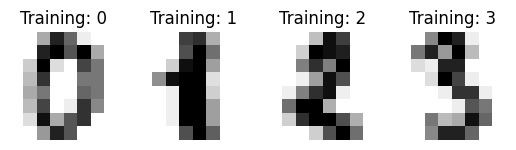

In [7]:
print("Lê Anh Pha - 6451071056")

# The digits dataset
digits = datasets.load_digits()

_, axes = plt.subplots(1, 4)
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes, images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Training: %i' % label)
plt.show()

Bước 3: Chuyển ảnh 8x8 thành vector 1x64

In [8]:
print("Lê Anh Pha - 6451071056")

n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))
print(data.shape)      # (1797, 64)

Lê Anh Pha - 6451071056
(1797, 64)


Bước 4: Tạo cây ID3, chia 80% huấn luyện / 20% kiểm thử, huấn luyện

In [9]:
print("Lê Anh Pha - 6451071056")

# Create a classifier: a decision tree classifier
classifier = tree.DecisionTreeClassifier(criterion="entropy", random_state=33)

# Split data into train and test subsets
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.2, shuffle=False)

# We learn the digits on the first part of the digits
classifier.fit(X_train, y_train)

Lê Anh Pha - 6451071056


DecisionTreeClassifier(criterion='entropy', random_state=33)

Bước 5: Dự đoán và hiển thị một vài kết quả

Lê Anh Pha - 6451071056


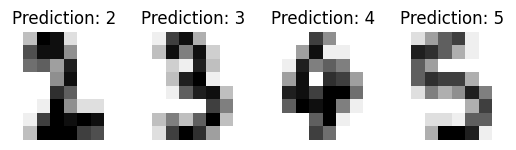

In [10]:
print("Lê Anh Pha - 6451071056")

predicted = classifier.predict(X_test)

# Test set là phần cuối của dữ liệu (shuffle=False)
test_images = digits.images[-len(X_test):]

_, axes = plt.subplots(1, 4)
images_and_predictions = list(zip(test_images, predicted))
for ax, (image, prediction) in zip(axes, images_and_predictions[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Prediction: %i' % prediction)
plt.show()

Bước 6: Thông số của cây ID3 và ma trận nhầm lẫn

Lê Anh Pha - 6451071056
Classification report for classifier DecisionTreeClassifier(criterion='entropy', random_state=33):
              precision    recall  f1-score   support

           0       0.86      0.89      0.87        35
           1       0.72      0.64      0.68        36
           2       0.76      0.74      0.75        35
           3       0.69      0.59      0.64        37
           4       0.86      0.84      0.85        37
           5       0.80      0.95      0.86        37
           6       0.97      0.95      0.96        37
           7       0.78      0.86      0.82        36
           8       0.79      0.82      0.81        33
           9       0.72      0.70      0.71        37

    accuracy                           0.80       360
   macro avg       0.80      0.80      0.79       360
weighted avg       0.80      0.80      0.79       360


Confusion matrix:
[[31  0  0  0  1  0  0  0  1  2]
 [ 0 23  0  2  2  0  0  1  1  7]
 [ 1  2 26  0  0  1  0  3  2  0]


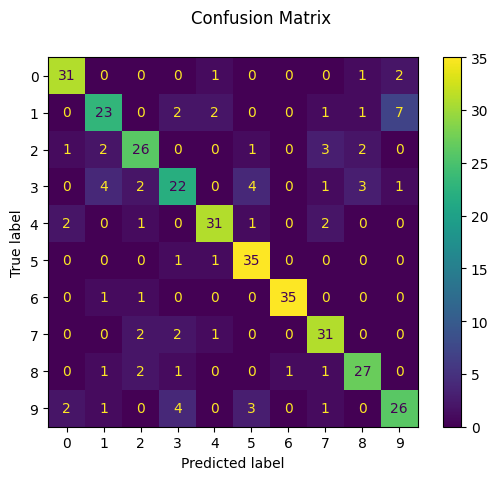

In [11]:
print("Lê Anh Pha - 6451071056")

print("Classification report for classifier %s:\n%s\n"
      % (classifier, metrics.classification_report(y_test, predicted)))

disp = metrics.ConfusionMatrixDisplay.from_estimator(classifier, X_test, y_test)
disp.figure_.suptitle("Confusion Matrix")
print("Confusion matrix:\n%s" % disp.confusion_matrix)
plt.show()

Bước 7: Xem ảnh gốc

Lê Anh Pha - 6451071056


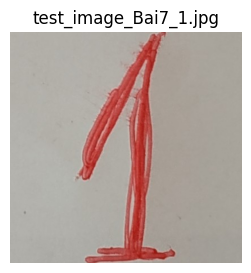

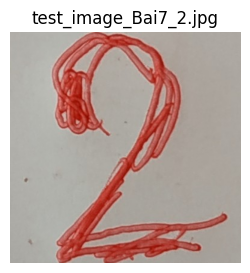

In [12]:
print("Lê Anh Pha - 6451071056")

for name in ['test_image_Bai7_1.jpg', 'test_image_Bai7_2.jpg']:
    plt.figure(figsize=(3, 3))
    plt.imshow(Image.open(name))
    plt.title(name)
    plt.axis('off')
    plt.show()

Bước 8: Đọc ảnh, đảo màu và hiển thị ảnh 8x8

Lê Anh Pha - 6451071056


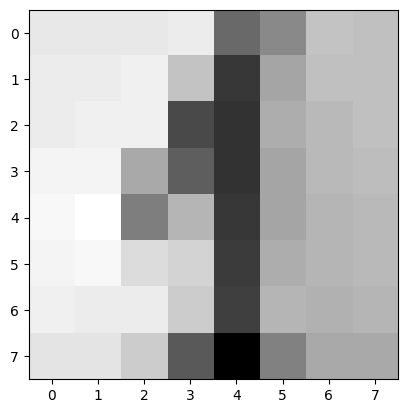

In [13]:
print("Lê Anh Pha - 6451071056")

# Open image
img = Image.open('test_image_Bai7_1.jpg').convert("L").resize((8, 8))
# Invert image
img = ImageOps.invert(img)
# Convert to numpy array
im2arr = np.array(img)
# Show
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()

Bước 9: Làm rõ nét (phân biệt đen, trắng)

Lê Anh Pha - 6451071056
[[  0   0   0   0 155   0   0   0   0   0   0   0 155   0   0   0   0   0
    0 155 155   0   0   0   0   0   0 155 155   0   0   0   0   0   0   0
  155   0   0   0   0   0   0   0 155   0   0   0   0   0   0   0 155   0
    0   0   0   0   0 155 155   0   0   0]]


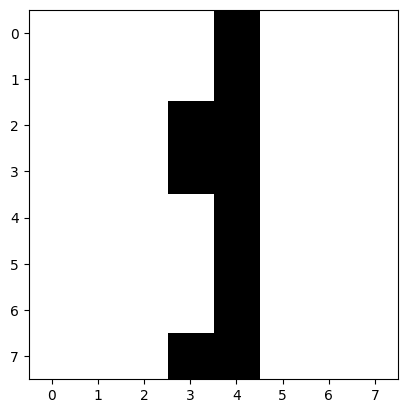

In [14]:
print("Lê Anh Pha - 6451071056")

# Change from 2d array (8x8) to 1d array (1x64)
img1d = im2arr.reshape([1, 64])
# Normalize black & white image array
img1d[img1d > 109] = 155
img1d[img1d < 110] = 0
print(img1d)

# After normalize
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()

Bước 10: Nhận diện bằng cây ID3

In [15]:
print("Lê Anh Pha - 6451071056")

# Predict label of number
y_pred = classifier.predict(img1d)
print(y_pred)

Lê Anh Pha - 6451071056
[1]


Bước 11: Làm tương tự cho ảnh thứ hai (dùng hàm gọn để tránh chép lại ba bước trên)

Lê Anh Pha - 6451071056


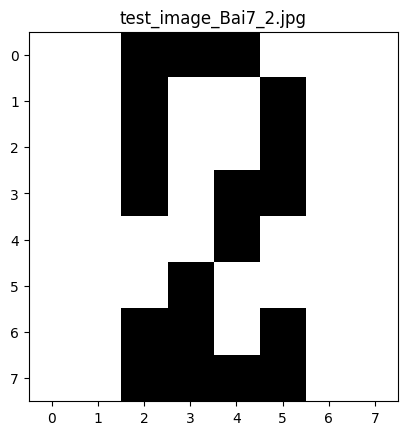

test_image_Bai7_2.jpg -> dự đoán: [2]


In [16]:
print("Lê Anh Pha - 6451071056")

def nhan_dang(name, nguong=110, dao_mau=True):
    img = Image.open(name).convert("L").resize((8, 8))
    if dao_mau:
        img = ImageOps.invert(img)
    im2arr = np.array(img)
    img1d = im2arr.reshape([1, 64])
    img1d[img1d > nguong - 1] = 155
    img1d[img1d < nguong] = 0
    plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')
    plt.title(name)
    plt.show()
    print(name, "-> dự đoán:", classifier.predict(img1d))

nhan_dang('test_image_Bai7_2.jpg')